In [14]:
library(data.table)
library(dplyr)
library(ggplot2)
library(GenomicRanges)
library(rtracklayer)
library(GSEABase)
library(ChIPQC)

# SRF and PGR GD2.5 ChIPseq data analysis

This notebook performs high-level data analysis on the raw data output by the ChIPseq pipeline defined by the `Snakefile` in this directory.

## Generating the raw results for this notebook

To generate the raw results for analysis by this notebook, two steps need to be performed.

### Step 1: download the prerequisite programs

The following command-line programs are required:

* FastQC
* MultiQC
* Trimmomatic
* HISAT2
* Gzip
* SAMtools
* Subread
* DeepTools
* HOMER
* MACS
* Wget
* BEDtools

In addition, the following Python packages are required:

* os
* time
* subprocess
* joblib

And the following R packages are required:

* data.table
* ggplot2
* GenomicRanges
* rtracklayer

You will also need to use the following publicly available web tools:

* GREAT (from Stanford). **This can be supplanted with `clusterProfiler`, but hasn't been implemented yet. `clusterProfiler` does a bad job of documenting what it's doing, so I originally used GREAT.**

Most of these tools are standard, but if you wish to guarantee that your system can handle the following requirements, you can perform the following steps:

1. Install [`conda`](https://docs.conda.io/projects/conda/en/latest/user-guide/install/index.html). (The faster reimplementation, [`mamba`](https://mamba.readthedocs.io/en/latest/installation/mamba-installation.html), is preferred.)
2. Create and activate a new `conda` environment using your preferred version of Python.
3. Run the following command to install all of the following prerequisites at once (if using `mamba`, replace `conda` with `mamba`:

```sh
mamba install -y bioconda::fastqc bioconda::multiqc bioconda::trimmomatic bioconda::hisat2 conda-forge::gzip bioconda::samtools bioconda::subread bioconda::deeptools bioconda::homer conda-forge::wget bioconda::bedtools bioconda::snakemake joblib
```

That's it! You should have the appropriate programs needed to run the result generation pipeline.

### Step 2: create your data

Navigate to the directory containing the `Snakefile` and create a folder named `data` (if not already present). This pipeline takes in FASTQ files containing raw sequencing data. The data need to be placed in the appropriate directory structure before proceeding:

```
data/
    group-1/
         file-1.fastq[.gz]
         file-2.fastq[.gz]
         ...
    group-2/
         ...
    control-<rest of name>/
         ...
```

Each of the FASTQ files in the group directories will be treated as ONE REPLICATE, simply concatenating all of the relevant reads to an associated SAM file (which will then be processed).

### Step 3: run `snakemake`

Again navigate to the directory containing the `Snakefile` and execute the following command:

```sh
snakemake -p --cores [cores]
```

This will run the analysis using `[cores]` number of CPUs. Let this go, and eventually you should have your results.

## High-level analysis

Using the results that have been generated, I will now make summary graphs and charts to visualize the ChIPseq data that has been generated by the `snakemake` pipeline for this project.

### ChIPQC

In [2]:
## Read in the ChIPseq metadata.

metadata <- fread('results/metadata.csv')
head(metadata)

SampleID,Factor,Replicate,bamReads,ControlID,bamControl,Peaks,PeakCaller,Tissue,Condition
<chr>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<lgl>
PGR.Rep1,PGR,1,results/aligned/processed/NS50818-DeMayo-Wu.deduplicate.bam,Input1,results/aligned/processed/CONTROL-NS50850-DeMayo-Wu.deduplicate.bam,results/analysis/NS50818-DeMayo-Wu/peaks/macs3_peaks.narrowPeak,narrow,Oviduct,NA
SRF.Rep1,SRF,1,results/aligned/processed/NS51381-DeMayo-Hewitt.deduplicate.bam,Input1,results/aligned/processed/CONTROL-NS50850-DeMayo-Wu.deduplicate.bam,results/analysis/NS51381-DeMayo-Hewitt/peaks/macs3_peaks.narrowPeak,narrow,Oviduct,NA


In [3]:
## Generate the QC object; this might take a few minutes.

chip_obj <- ChIPQC(metadata, annotation="mm10") 

PGR.Rep1 Oviduct PGR   1 narrow

SRF.Rep1 Oviduct SRF   1 narrow

Checking chromosomes:



[1] "chr1"


Compiling annotation...

Computing metrics for 3 samples...

Executing in parallel - max 46 cores.



In [4]:
## Generate and record the QC report.

chip_dir <- "results/qc/chip"

dir.create(chip_dir, recursive = TRUE, showWarnings = FALSE)
ChIPQCreport(chip_obj, reportName="ChIPQC", reportFolder = chip_dir)

Saving 6.67 x 6.67 in image
Saving 6.67 x 6.67 in image
Saving 6.67 x 6.67 in image
Using Sample as id variables

Saving 6.67 x 6.67 in image
Saving 6.67 x 6.67 in image


### Peak annotation distribution using HOMER

In [5]:
# Read in the annotations and display the first couple of entries.
annpeaks_pgr <- fread("./results/analysis/NS50818-DeMayo-Wu/annotated_peaks.txt")
annpeaks_srf <- fread("./results/analysis/NS51381-DeMayo-Hewitt/annotated_peaks.txt")
colnames(annpeaks_pgr)[1] <- "PeakID"
colnames(annpeaks_srf)[1] <- "PeakID"
head(annpeaks_pgr)
head(annpeaks_srf)

PeakID,Chr,Start,End,Strand,Peak Score,Focus Ratio/Region Size,Annotation,Detailed Annotation,Distance to TSS,Nearest PromoterID,Entrez ID,Nearest Unigene,Nearest Refseq,Nearest Ensembl,Gene Name,Gene Alias,Gene Description,Gene Type
<chr>,<chr>,<int>,<int>,<chr>,<int>,<lgl>,<chr>,<chr>,<int>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
macs3_peak_13468,chr17,28516553,28521291,+,7450,NA,Intergenic,Intergenic,-11939,NM_026290,67645,Mm.46170,NM_026290,ENSMUSG00000024223,Armc12,4930511I11Rik|AV041658,armadillo repeat containing 12,protein-coding
macs3_peak_12189,chr16,25058322,25060739,+,6341,NA,promoter-TSS (NR_040374),promoter-TSS (NR_040374),-109,NR_040374,319487,Mm.137341,NR_040374,ENSMUSG00000096960,A230028O05Rik,-,RIKEN cDNA A230028O05 gene,ncRNA
macs3_peak_15853,chr19,23055724,23059558,+,6091,NA,Intergenic,Intergenic,-83585,NM_010638,16601,Mm.291595,NM_010638,ENSMUSG00000033863,Klf9,2310051E17Rik|AA589643|BTEB-1|Bteb1|Gm9971,Kruppel-like factor 9,protein-coding
macs3_peak_4680,chr11,69094427,69101060,+,5915,NA,Intergenic,Intergenic,-1206,NM_011065,18626,Mm.7373,NM_011065,ENSMUSG00000020893,Per1,Hftm|Per|m-rigui|mPer1,period circadian clock 1,protein-coding
macs3_peak_27851,chr7,63896091,63898105,+,5722,NA,"intron (NM_021366, intron 1 of 1)",CpG,-19759,NM_001256311,381994,Mm.425466,NM_001256311,ENSMUSG00000095061,E030018B13Rik,Gm1697,RIKEN cDNA E030018B13 gene,protein-coding
macs3_peak_15855,chr19,23133524,23137047,+,5612,NA,Intergenic,CpG,-5941,NM_010638,16601,Mm.291595,NM_010638,ENSMUSG00000033863,Klf9,2310051E17Rik|AA589643|BTEB-1|Bteb1|Gm9971,Kruppel-like factor 9,protein-coding


PeakID,Chr,Start,End,Strand,Peak Score,Focus Ratio/Region Size,Annotation,Detailed Annotation,Distance to TSS,Nearest PromoterID,Entrez ID,Nearest Unigene,Nearest Refseq,Nearest Ensembl,Gene Name,Gene Alias,Gene Description,Gene Type
<chr>,<chr>,<int>,<int>,<chr>,<int>,<lgl>,<chr>,<chr>,<int>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
macs3_peak_947,chr18,34860048,34861591,+,7776,NA,promoter-TSS (NM_007913),promoter-TSS (NM_007913),-388,NM_007913,13653,Mm.181959,NM_007913,ENSMUSG00000038418,Egr1,A530045N19Rik|ETR103|Egr-1|Krox-1|Krox-24|Krox24|NGF1-A|NGFI-A|NGFIA|TIS8|Zenk|Zfp-6|Zif268|egr,early growth response 1,protein-coding
macs3_peak_642,chr14,70074501,70075542,+,6543,NA,Intergenic,CpG,-2296,NM_018781,13655,Mm.103737,NM_018781,ENSMUSG00000033730,Egr3,Pilot,early growth response 3,protein-coding
macs3_peak_550,chr13,93303242,93304031,+,6213,NA,promoter-TSS (NM_147176),promoter-TSS (NM_147176),-121,NM_147176,26556,Mm.37533,NM_011982,ENSMUSG00000007617,Homer1,PSD-Zip45|SYN47|Ves-1|homer-1|vesl-1,homer scaffolding protein 1,protein-coding
macs3_peak_384,chr11,103267230,103267996,+,5919,NA,promoter-TSS (NM_016896),promoter-TSS (NM_016896),-212,NM_016896,53859,Mm.158981,NM_016896,ENSMUSG00000020941,Map3k14,Nik|aly,mitogen-activated protein kinase kinase kinase 14,protein-coding
macs3_peak_564,chr13,107889890,107890645,+,5580,NA,promoter-TSS (NM_145456),promoter-TSS (NM_145456),-203,NM_145456,67263,Mm.490418,NM_145456,,Zswim6,2900036G02Rik|mKIAA1577,zinc finger SWIM-type containing 6,protein-coding
macs3_peak_325,chr11,69661856,69662723,+,5531,NA,promoter-TSS (NR_035455),promoter-TSS (NR_035455),360,NM_001301710,24070,Mm.89579,NM_011900,ENSMUSG00000018761,Mpdu1,LEC35|SL15|Supl15h,mannose-P-dolichol utilization defect 1,protein-coding


In [6]:
dim(annpeaks_pgr)
dim(annpeaks_srf)

[1] 33876    19

[1] 2264   19


      3' UTR       5' UTR         EXON   INTERGENIC       INTRON   NON-CODING 
   0.7116912    3.8449045    5.5133922   34.5598441   33.1718985    0.8239081 
PROMOTER-TSS          TTS 
  19.8712459    1.5031155 


      3' UTR       5' UTR         EXON   INTERGENIC       INTRON   NON-CODING 
   0.4875887    0.8865248    0.5319149   31.9148936   34.8847518    0.3546099 
PROMOTER-TSS          TTS 
  29.2996454    1.6400709 

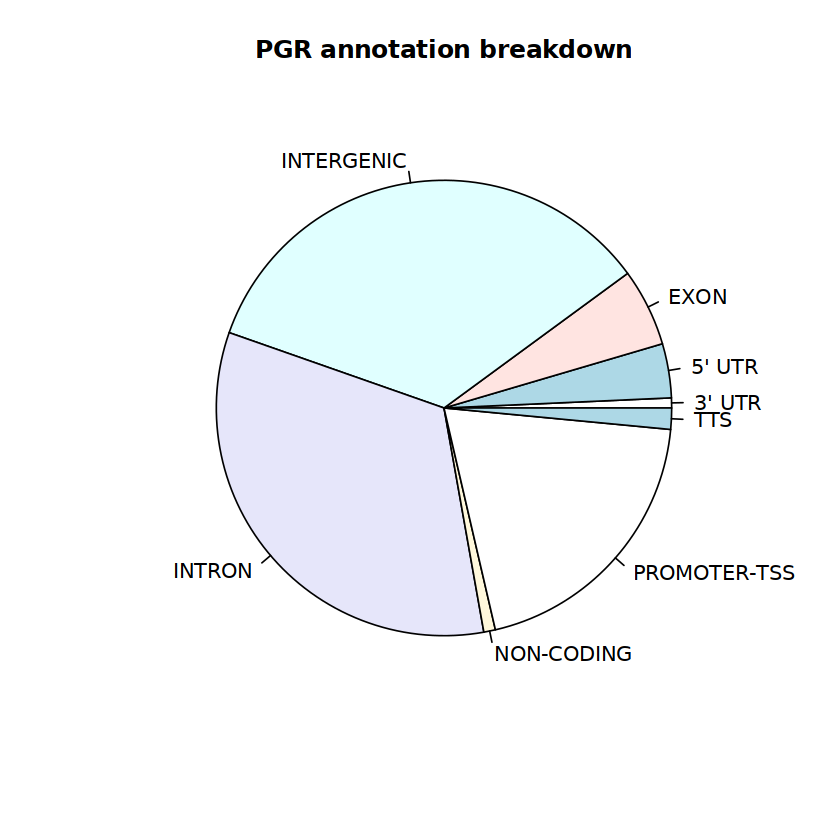

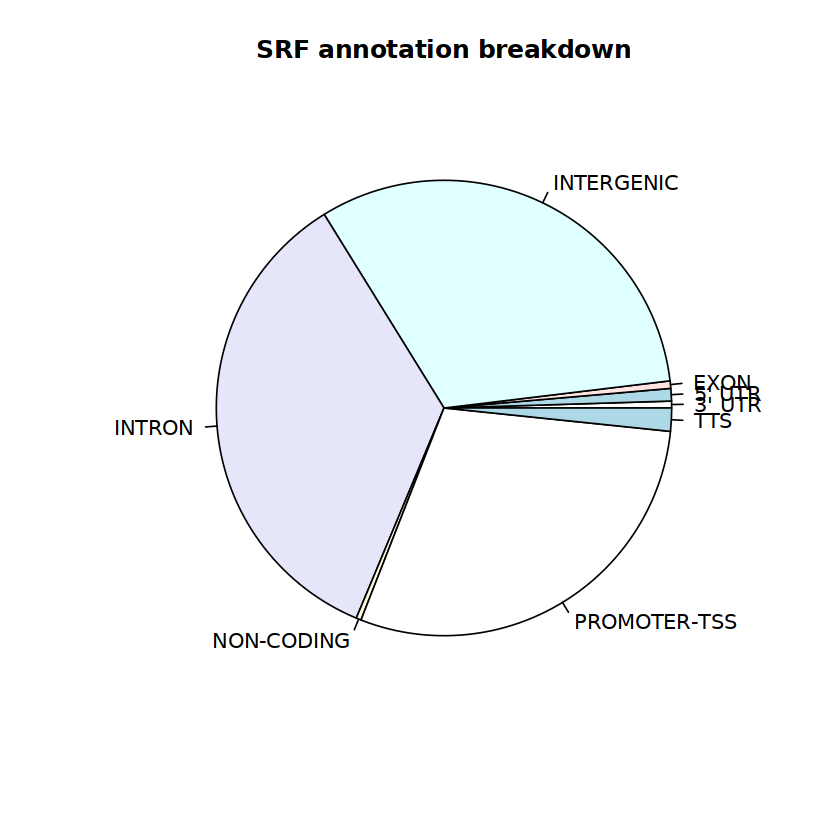

In [7]:
## Make the distributions of specific regions present in each of the ChIPseq data sequences.

# Functions for scraping annotation types.
coarse_anns <- function(annotation_vector) {
    return(gsub("\\W*\\(.+", "", toupper(annotation_vector)))
}
generate_anndist <- function(annotation_vector) {
    return(table(coarse_anns(annotation_vector)))
}

# Scrape annotation types from each run.
anndist_pgr <- generate_anndist(annpeaks_pgr$Annotation)
anndist_srf <- generate_anndist(annpeaks_srf$Annotation)

# Display the percentages.
anndist_pgr / sum(anndist_pgr) * 100
anndist_srf / sum(anndist_srf) * 100

# Display the annotation types.
pie(anndist_pgr, main = "PGR annotation breakdown")
pie(anndist_srf, main = "SRF annotation breakdown")

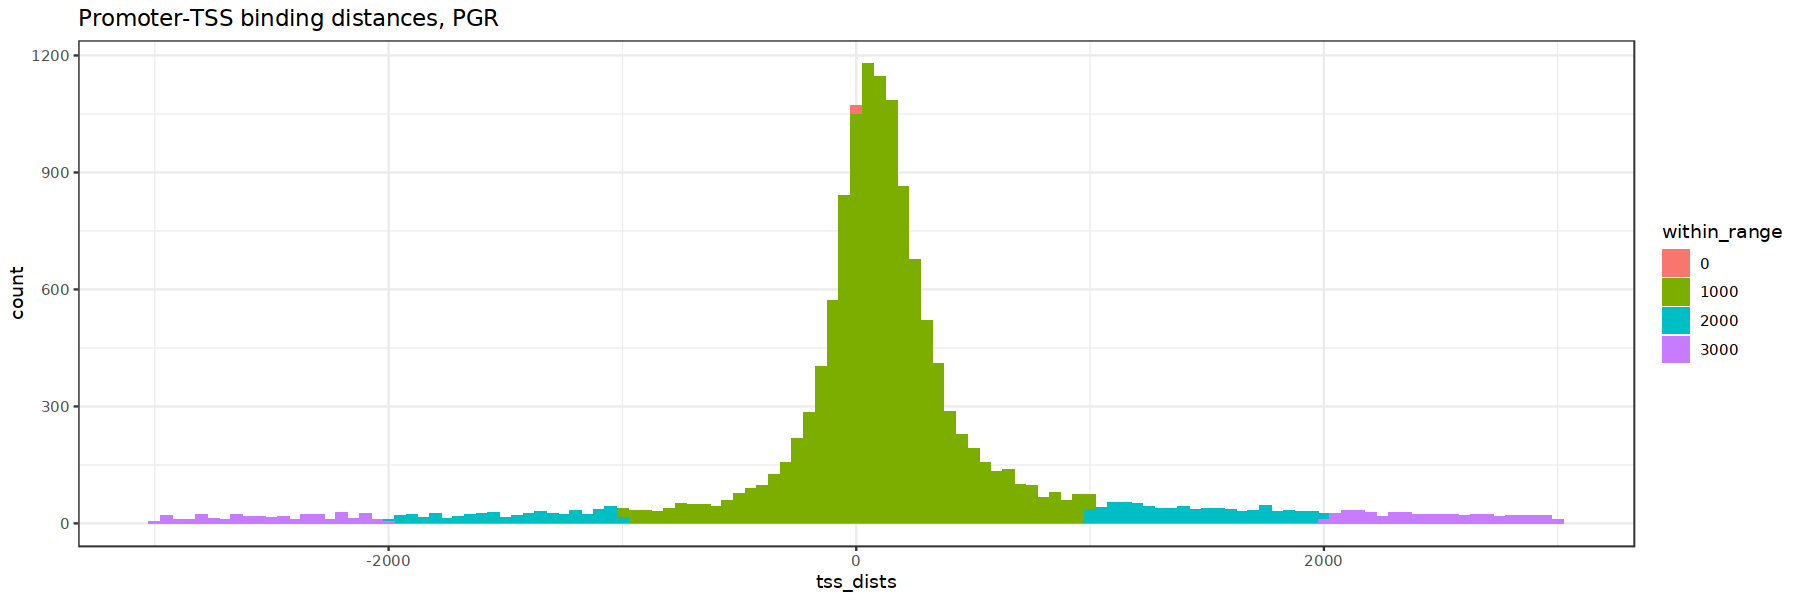

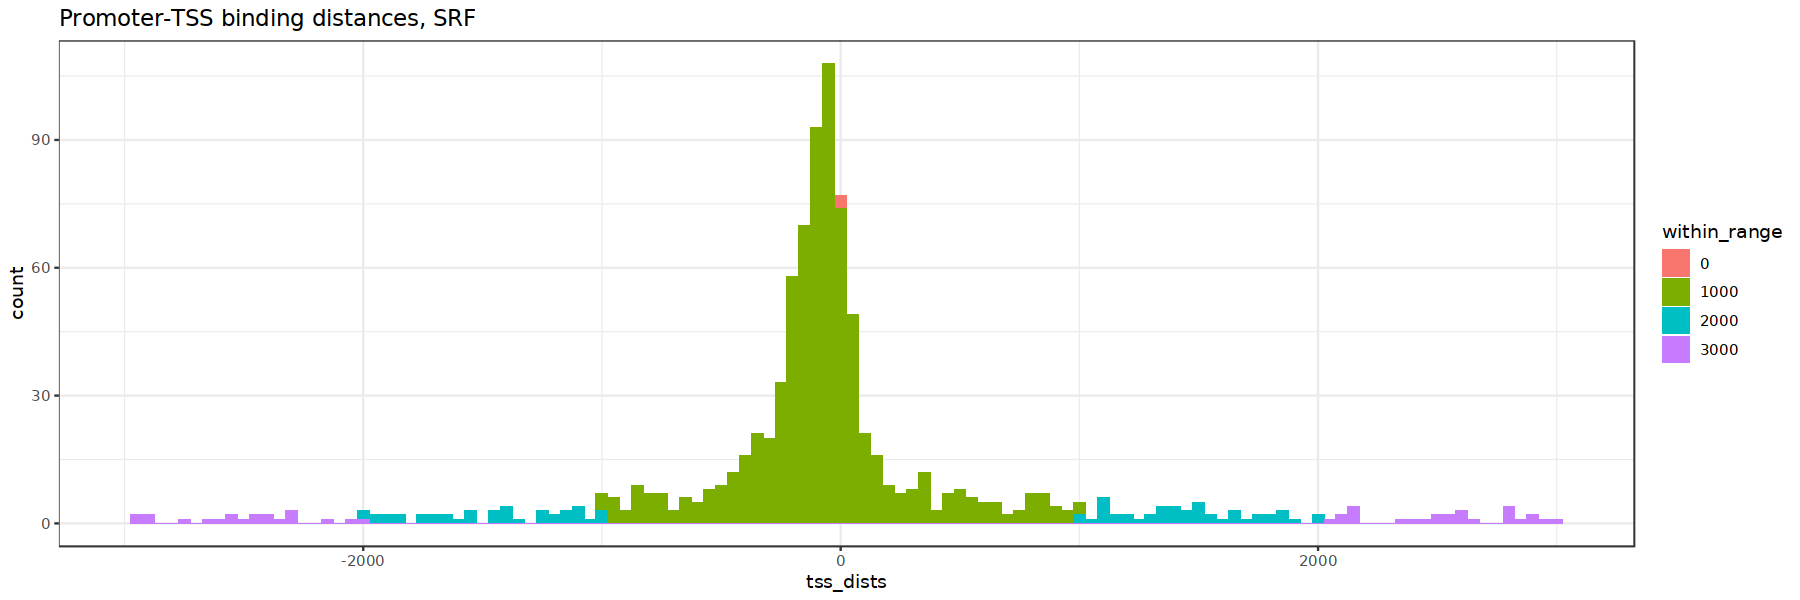

In [16]:
## Plot the distributions for TSS sites.

# Function for plotting within a certain base cutoff range.
# Note the cutoff is inclusive.
create_tss_hist <- function(tss_dists, title, cutoff = 3000) {
    df <- data.table(tss_dists = tss_dists)
    df$within_range <- ceiling(abs(df$tss_dists / 1000)) * 1000
    df <- df %>% filter(within_range <= cutoff)
    df$within_range <- factor(df$within_range)
    return(ggplot(df, aes(x = tss_dists, fill = within_range)) + geom_histogram(binwidth = 50)
           + theme_bw() + ggtitle(title))
}

coarseanns_pgr <- coarse_anns(annpeaks_pgr$Annotation)
tss_dists_pgr <- annpeaks_pgr[["Distance to TSS"]]
coarseanns_srf <- coarse_anns(annpeaks_srf$Annotation)
tss_dists_srf <- annpeaks_srf[["Distance to TSS"]]

saved <- options(repr.plot.width = 15)
create_tss_hist(tss_dists_pgr, title = "Promoter-TSS binding distances, PGR") 
create_tss_hist(tss_dists_srf, title = "Promoter-TSS binding distances, SRF")
options(saved)

### Gene ontology (GO) analysis using GREAT

For Gene Ontology analysis, we use the results output by GREAT (great.stanford.edu). This is because HOMER does not support "GO slims," which would allow us to effectively delete overly broard terms from the main GO database that we don't wish to use. We can't prompt HOMER to use GO slim files either.

**Bug:** Data exported from GREAT ("Download all data as .tsv") is different from only *visible* data being exported from GREAT ("Download shown data as .tsv"). The cause is unclear. I'm picking the first option.

GREAT is purely a web-based tool, so I've fed results into that and simply loaded them here.

If you hope to use `ChIPseeker` in the future, ensure you know the following:

* Use OrgDb AH114085 in AnnotationHub.
* The OrgDb uses the following GO slim: http://current.geneontology.org/ontology/go-basic.obo

In [10]:
## Load the preprocessed GO BP results by GREAT.

go_pgr <- fread("./results/analysis/NS50818-DeMayo-Wu/gene_ontology/great/all.tsv", sep = "\t", fill = TRUE, skip = 3)
go_srf <- fread("./results/analysis/NS51381-DeMayo-Hewitt/gene_ontology/great/all.tsv", sep = "\t", fill = TRUE, skip = 3)

head(go_pgr)
head(go_srf)

# Ontology,ID,Desc,BinomRank,BinomP,BinomBonfP,BinomFdrQ,RegionFoldEnrich,ExpRegions,ObsRegions,⋯,HyperBonfP,HyperFdrQ,GeneFoldEnrich,ExpGenes,ObsGenes,TotalGenes,GeneSetCov,TermCov,Regions,Genes
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<chr>,<chr>
Ensembl Genes,16149,Hrh1,1,5.506084e-99,1.178027e-94,1.178027e-94,22.648220,4.547818,103,⋯,1,1,1.402307,0.7131105,1,1,6.554368e-05,1,"macs3_peak_26440,macs3_peak_26441,macs3_peak_26442,macs3_peak_26443,macs3_peak_26444,macs3_peak_26445,macs3_peak_26446,macs3_peak_26447,macs3_peak_26448,macs3_peak_26449,macs3_peak_26450,macs3_peak_26451,macs3_peak_26452,macs3_peak_26453,macs3_peak_26454,macs3_peak_26455,macs3_peak_26456,macs3_peak_26457,macs3_peak_26458,macs3_peak_26459,macs3_peak_26460,macs3_peak_26461,macs3_peak_26462,macs3_peak_26463,macs3_peak_26464,macs3_peak_26465,macs3_peak_26466,macs3_peak_26467,macs3_peak_26468,macs3_peak_26469,macs3_peak_26470,macs3_peak_26471,macs3_peak_26472,macs3_peak_26473,macs3_peak_26474,macs3_peak_26475,macs3_peak_26476,macs3_peak_26477,macs3_peak_26478,macs3_peak_26479,macs3_peak_26480,macs3_peak_26481,macs3_peak_26482,macs3_peak_26483,macs3_peak_26484,macs3_peak_26485,macs3_peak_26486,macs3_peak_26487,macs3_peak_26488,macs3_peak_26489,macs3_peak_26490,macs3_peak_26491,macs3_peak_26492,macs3_peak_26493,macs3_peak_26494,macs3_peak_26495,macs3_peak_26496,macs3_peak_26497,macs3_peak_26498,macs3_peak_26499,macs3_peak_26500,macs3_peak_26501,macs3_peak_26502,macs3_peak_26503,macs3_peak_26504,macs3_peak_26505,macs3_peak_26506,macs3_peak_26507,macs3_peak_26508,macs3_peak_26509,macs3_peak_26510,macs3_peak_26511,macs3_peak_26512,macs3_peak_26513,macs3_peak_26514,macs3_peak_26515,macs3_peak_26516,macs3_peak_26517,macs3_peak_26518,macs3_peak_26519,macs3_peak_26520,macs3_peak_26521,macs3_peak_26522,macs3_peak_26523,macs3_peak_26524,macs3_peak_26525,macs3_peak_26526,macs3_peak_26527,macs3_peak_26528,macs3_peak_26529,macs3_peak_26530,macs3_peak_26531,macs3_peak_26532,macs3_peak_26533,macs3_peak_26534,macs3_peak_26535,macs3_peak_26536,macs3_peak_26537,macs3_peak_26538,macs3_peak_26539,macs3_peak_26540,macs3_peak_26541,macs3_peak_26542",Hrh1
Ensembl Genes,16150,Atg7,2,2.926854e-92,6.262004e-88,3.131002e-88,16.578010,6.695618,111,⋯,1,1,1.402307,0.7131105,1,1,6.554368e-05,1,"macs3_peak_26442,macs3_peak_26443,macs3_peak_26444,macs3_peak_26445,macs3_peak_26446,macs3_peak_26447,macs3_peak_26448,macs3_peak_26449,macs3_peak_26450,macs3_peak_26451,macs3_peak_26452,macs3_peak_26453,macs3_peak_26454,macs3_peak_26455,macs3_peak_26456,macs3_peak_26457,macs3_peak_26458,macs3_peak_26459,macs3_peak_26460,macs3_peak_26461,macs3_peak_26462,macs3_peak_26463,macs3_peak_26464,macs3_peak_26465,macs3_peak_26466,macs3_peak_26467,macs3_peak_26468,macs3_peak_26469,macs3_peak_26470,macs3_peak_26471,macs3_peak_26472,macs3_peak_26473,macs3_peak_26474,macs3_peak_26475,macs3_peak_26476,macs3_peak_26477,macs3_peak_26478,macs3_peak_26479,macs3_peak_26480,macs3_peak_26481,macs3_peak_26482,macs3_peak_26483,macs3_peak_26484,macs3_peak_26485,macs3_peak_26486,macs3_peak_26487,macs3_peak_26488,macs3_peak_26489,macs3_peak_26490,macs3_peak_26491,macs3_peak_26492,macs3_peak_26493,macs3_peak_26494,macs3_peak_26495,macs3_peak_26496,macs3_peak_26497,macs3_peak_26498,macs3_peak_26499,macs3_peak_26500,macs3_peak_26501,macs3_peak_26502,macs3_peak_26503,macs3_peak_26504,macs3_peak_26505,macs3_peak_26506,macs3_peak_26507,macs3_peak_26508,macs3_peak_26509,macs3_peak_26510,macs3_peak_26511,macs3_peak_26512,macs3_peak_26513,macs3_peak_26514,macs3_peak_26515,macs3_peak_26516,macs3_peak_26517,macs3_peak_26518,macs3_peak_26519,macs3_peak_26520,macs3_peak_26521,macs3_peak_26522,macs3_peak_26523,macs3_peak_26524,macs3_peak_26525,macs3_peak_26526,macs3_peak_26527,macs3_peak_26528,macs3_peak_26529,macs3_peak_26530,macs3_peak_26531,macs3_peak_26532,macs3_peak_26533,macs3_peak_26534,macs3_peak_26535,macs3_peak_26536,macs3_peak_26537,macs3_peak_26538,macs3_pe

# Ontology,ID,Desc,BinomRank,BinomP,BinomBonfP,BinomFdrQ,RegionFoldEnrich,ExpRegions,ObsRegions,⋯,HyperBonfP,HyperFdrQ,GeneFoldEnrich,ExpGenes,ObsGenes,TotalGenes,GeneSetCov,TermCov,Regions,Genes
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<chr>,<chr>
Ensembl Genes,15687,Pdia4,1,1.141449e-64,2.442130e-60,2.442130e-60,214.6804,0.153716800,33,⋯,1,1,7.737794,0.1292358,1,1,0.0003616637,1,"macs3_peak_1608,macs3_peak_1609,macs3_peak_1610,macs3_peak_1611,macs3_peak_1612,macs3_peak_1613,macs3_peak_1614,macs3_peak_1615,macs3_peak_1616,macs3_peak_1617,macs3_peak_1618,macs3_peak_1619,macs3_peak_1620,macs3_peak_1621,macs3_peak_1622,macs3_peak_1623,macs3_peak_1624,macs3_peak_1625,macs3_peak_1626,macs3_peak_1627,macs3_peak_1628,macs3_peak_1629,macs3_peak_1630,macs3_peak_1631,macs3_peak_1632,macs3_peak_1633,macs3_peak_1634,macs3_peak_1635,macs3_peak_1636,macs3_peak_1637,macs3_peak_1638,macs3_peak_1639,macs3_peak_1640",Pdia4
Ensembl Genes,15686,Ezh2,2,4.808515e-57,1.028782e-52,5.143909e-53,125.7118,0.262505100,33,⋯,1,1,7.737794,0.1292358,1,1,0.0003616637,1,"macs3_peak_1608,macs3_peak_1609,macs3_peak_1610,macs3_peak_1611,macs3_peak_1612,macs3_peak_1613,macs3_peak_1614,macs3_peak_1615,macs3_peak_1616,macs3_peak_1617,macs3_peak_1618,macs3_peak_1619,macs3_peak_1620,macs3_peak_1621,macs3_peak_1622,macs3_peak_1623,macs3_peak_1624,macs3_peak_1625,macs3_peak_1626,macs3_peak_1627,macs3_peak_1628,macs3_peak_1629,macs3_peak_1630,macs3_peak_1631,macs3_peak_1632,macs3_peak_1633,macs3_peak_1634,macs3_peak_1635,macs3_peak_1636,macs3_peak_1637,macs3_peak_1638,macs3_peak_1639,macs3_peak_1640",Ezh2
Ensembl Genes,19602,Gm17535,3,1.099517e-34,2.352417e-30,7.841389e-31,1528.9790,0.007848374,12,⋯,1,1,7.737794,0.1292358,1,1,0.0003616637,1,"macs3_peak_2048,macs3_peak_2049,macs3_peak_2050,macs3_peak_2051,macs3_peak_2052,macs3_peak_2053,macs3_peak_2054,macs3_peak_2055,macs3_peak_2056,macs3_peak_2057,macs3_peak_2058,macs3_peak_2059",Gm17535
Ensembl Genes,19597,Gm10721,4,3.433870e-31,7.346765e-27,1.836691e-27,1313.9840,0.008371485,11,⋯,1,1,7.737794,0.1292358,1,1,0.0003616637,1,"macs3_peak_2021,macs3_peak_2022,macs3_peak_2023,macs3_peak_2024,macs3_peak_2025,macs3_peak_2026,macs3_peak_2027,macs3_peak_2028,macs3_peak_2029,macs3_peak_2030,macs3_peak_2031",Gm10721
Ensembl Genes,19596,Gm11168,5,7.128347e-29,1.525110e-24,3.050220e-25,1437.4300,0.006956863,10,⋯,1,1,7.737794,0.1292358,1,1,0.0003616637,1,"macs3_peak_2016,macs3_peak_2017,macs3_peak_2018,macs3_peak_2019,macs3_peak_2020,macs3_peak_2021,macs3_peak_2022,macs3_peak_2023,macs3_peak_2024,macs3_peak_2025",Gm11168
Ensembl Genes,19598,Gm10720,6,6.626219e-27,1.417680e-22,2.362799e-23,1754.8860,0.005128539,9,⋯,1,1,7.737794,0.1292358,1,1,0.0003616637,1,"macs3_peak_2028,macs3_peak_2029,macs3_peak_2030,macs3_peak_2031,macs3_peak_2032,macs3_peak_2033,macs3_peak_2034,macs3_peak_2035,macs3_peak_2036",Gm10720


In [11]:
## Filter out GO terms with low q-values via binomial or hypergeometric tests.

go_bp_pgr <- go_pgr %>% filter(BinomFdrQ < 0.05 & HyperFdrQ < 0.05 & `# Ontology` == "GO Biological Process")
go_bp_srf <- go_srf %>% filter(BinomFdrQ < 0.05 & HyperFdrQ < 0.05 & `# Ontology` == "GO Biological Process")

head(go_bp_pgr)
head(go_bp_srf)

# Ontology            ID        
1 GO Biological Process GO:0045638
2 GO Biological Process GO:1903706
3 GO Biological Process GO:1903707
4 GO Biological Process GO:0061014
5 GO Biological Process GO:0045637
6 GO Biological Process GO:0010608
  Desc                                                BinomRank BinomP       
1 negative regulation of myeloid cell differentiation 1         2.141816e-120
2 regulation of hemopoiesis                           2         1.331835e-112
3 negative regulation of hemopoiesis                  5          2.713894e-97
4 positive regulation of mRNA catabolic process       14         2.622350e-89
5 regulation of myeloid cell differentiation          20         6.673908e-82
6 posttranscriptional regulation of gene expression   21         1.177723e-77
  BinomBonfP    BinomFdrQ     RegionFoldEnrich ExpRegions ObsRegions ⋯
1 2.753947e-116 2.753947e-116 2.599484          303.5218   789       ⋯
2 1.712473e-108 8.562367e-109 1.686466         1244.0220  2098       ⋯
3  3.489525e-93  6.979050e-94 2.048630          509.6088  1044       ⋯
4  3.371818e-85  2.408441e-86 4.208568           70.3327   296       ⋯
5  8.581311e-78  4.290655e-79 1.798560          694.4446  1249       ⋯
6  1.514316e-73  7.211030e-75 1.679259          878.9592  1476       ⋯
  HyperBonfP   HyperFdrQ    GeneFoldEnrich ExpGenes  ObsGenes TotalGenes
1 1.000000e+00 2.679200e-03 1.223289        67.03239  82       94       
2 3.038186e-03 6.303290e-06 1.157460       269.55580 312      378       
3 8.914144e-01 1.041372e-03 1.192438       104.82720 125      147       
4 1.000000e+00 1.744049e-02 1.348372        18.54087  25       26       
5 1.618379e-01 2.292321e-04 1.178751       147.61390 174      207       
6 2.622923e-14 2.760971e-16 1.252823       280.96560 352      394       
  GeneSetCov  TermCov  
1 0.005374582 0.8723404
2 0.020449630 0.8253968
3 0.008192961 0.8503401
4 0.001638592 0.9615385
5 0.011404600 0.8405797
6 0.023071380 0.8934010
  Regions                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                          

# Ontology,ID,Desc,BinomRank,BinomP,BinomBonfP,BinomFdrQ,RegionFoldEnrich,ExpRegions,ObsRegions,⋯,HyperBonfP,HyperFdrQ,GeneFoldEnrich,ExpGenes,ObsGenes,TotalGenes,GeneSetCov,TermCov,Regions,Genes
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<chr>,<chr>
GO Biological Process,GO:0042542,response to hydrogen peroxide,15,2.280020e-21,2.931650e-17,1.954433e-18,3.746755,20.01732,75,⋯,1.000000e+00,1.204307e-02,1.970947,13.699000,27,106,0.009764919,0.2547170,"macs3_peak_1000,macs3_peak_1047,macs3_peak_1202,macs3_peak_1237,macs3_peak_1238,macs3_peak_1239,macs3_peak_1240,macs3_peak_1241,macs3_peak_1242,macs3_peak_1275,macs3_peak_1362,macs3_peak_1371,macs3_peak_1372,macs3_peak_1373,macs3_peak_1608,macs3_peak_1609,macs3_peak_1610,macs3_peak_1611,macs3_peak_1612,macs3_peak_1613,macs3_peak_1614,macs3_peak_1615,macs3_peak_1616,macs3_peak_1617,macs3_peak_1618,macs3_peak_1619,macs3_peak_1620,macs3_peak_1621,macs3_peak_1622,macs3_peak_1623,macs3_peak_1624,macs3_peak_1625,macs3_peak_1626,macs3_peak_1627,macs3_peak_1628,macs3_peak_1629,macs3_peak_1630,macs3_peak_1631,macs3_peak_1632,macs3_peak_1633,macs3_peak_1634,macs3_peak_1635,macs3_peak_1636,macs3_peak_1637,macs3_peak_1638,macs3_peak_1639,macs3_peak_1640,macs3_peak_1647,macs3_peak_189,macs3_peak_1939,macs3_peak_1968,macs3_peak_2065,macs3_peak_2160,macs3_peak_2161,macs3_peak_2162,macs3_peak_2163,macs3_peak_2164,macs3_peak_2165,macs3_peak_240,macs3_peak_352,macs3_peak_397,macs3_peak_407,macs3_peak_408,macs3_peak_409,macs3_peak_602,macs3_peak_611,macs3_peak_660,macs3_peak_70,macs3_peak_916,macs3_peak_917,macs3_peak_988,macs3_peak_991,macs3_peak_997,macs3_peak_998,macs3_peak_999","Ada,Aqp1,Bad,Bcl2,Cbx8,Cdk1,Col1a1,Cyp1b1,Ezh2,Fosl1,Foxo1,Gnao1,Jun,Klf2,Mapk8,Mdm2,Nr4a3,Pax2,Ppif,Rela,Rhob,Sdc1,Stk24,Trpc6,Txnip,mt-Nd5,mt-Nd6"
GO Biological Process,GO:2000134,negative regulation of G1/S transition of mitotic cell cycle,20,1.959121e-19,2.519038e-15,1.259519e-16,4.669391,11.35052,53,⋯,4.050712e-02,2.956724e-04,2.976075,6.720262,20,52,0.007233273,0.3846154,"macs3_peak_1083,macs3_peak_1211,macs3_peak_1234,macs3_peak_1608,macs3_peak_1609,macs3_peak_1610,macs3_peak_1611,macs3_peak_1612,macs3_peak_1613,macs3_peak_1614,macs3_peak_1615,macs3_peak_1616,macs3_peak_1617,macs3_peak_1618,macs3_peak_1619,macs3_peak_1620,macs3_peak_1621,macs3_peak_1622,macs3_peak_1623,macs3_peak_1624,macs3_peak_1625,macs3_peak_1626,macs3_peak_1627,macs3_peak_1628,macs3_peak_1629,macs3_peak_1630,macs3_peak_1631,macs3_peak_1632,macs3_peak_1633,macs3_peak_1634,macs3_peak_1635,macs3_peak_1636,macs3_peak_1637,macs3_peak_1638,macs3_peak_1639,macs3_peak_1640,macs3_peak_1858,macs3_peak_1888,macs3_peak_1959,macs3_peak_2071,macs3_peak_2148,macs3_peak_2153,macs3_peak_2223,macs3_peak_235,macs3_peak_236,macs3_peak_240,macs3_peak_249,macs3_peak_314,macs3_peak_48,macs3_peak_70,macs3_peak_770,macs3_peak_982,macs3_peak_99","Bcl2,Brd7,Cdc73,Cdk2ap2,Ctdsp1,Ctdsp2,Ctdspl,Dcun1d3,E2f7,Ezh2,Fhl1,Jade1,Kank2,Mdm2,Myo16,Nacc2,Ppp2r3d,Rbm38,Rpl26,Trp63"
GO Biological Process,GO:1902807,negative regulation of cell cycle G1/S phase transition,22,3.968260e-19,5.102389e-15,2.319268e-16,4.591623,11.54276,53,⋯,1.103020e-01,6.725730e-04,2.813743,7.107969,20,55,0.007233273,0.3636364,"macs3_peak_1083,macs3_peak_1211,macs3_peak_1234,macs3_peak_1608,macs3_peak_1609,macs3_peak_1610,macs3_peak_1611,macs3_peak_1612,macs3_peak_1613,macs3_peak_1614,macs3_peak_1615,macs3_peak_1616,macs3_peak_1617,macs3_peak_1618,macs3_peak_1619,macs3_peak_1620,macs3_peak_1621,macs3_peak_1622,macs3_peak_1623,macs3_peak_1624,macs3_peak_1625,macs3_peak_1626,macs3_peak_1627,macs3_peak_1628,macs3_peak_1629,macs3_peak_1630,macs3_peak_1631,macs3_peak_1632,macs3_peak_1633,macs3_peak_1634,macs3_peak_1635,macs3_peak_1636,macs3_peak_1637,macs3_peak_1638,macs3_peak_1639,macs3_peak_1640,macs3_peak_1858,macs3_peak_1888,macs3_peak_1959,macs3_peak_2071,macs3_peak_2148,macs3_peak_2153,macs3_peak_2223,macs3_peak_235,macs3_peak_236,macs3_pea

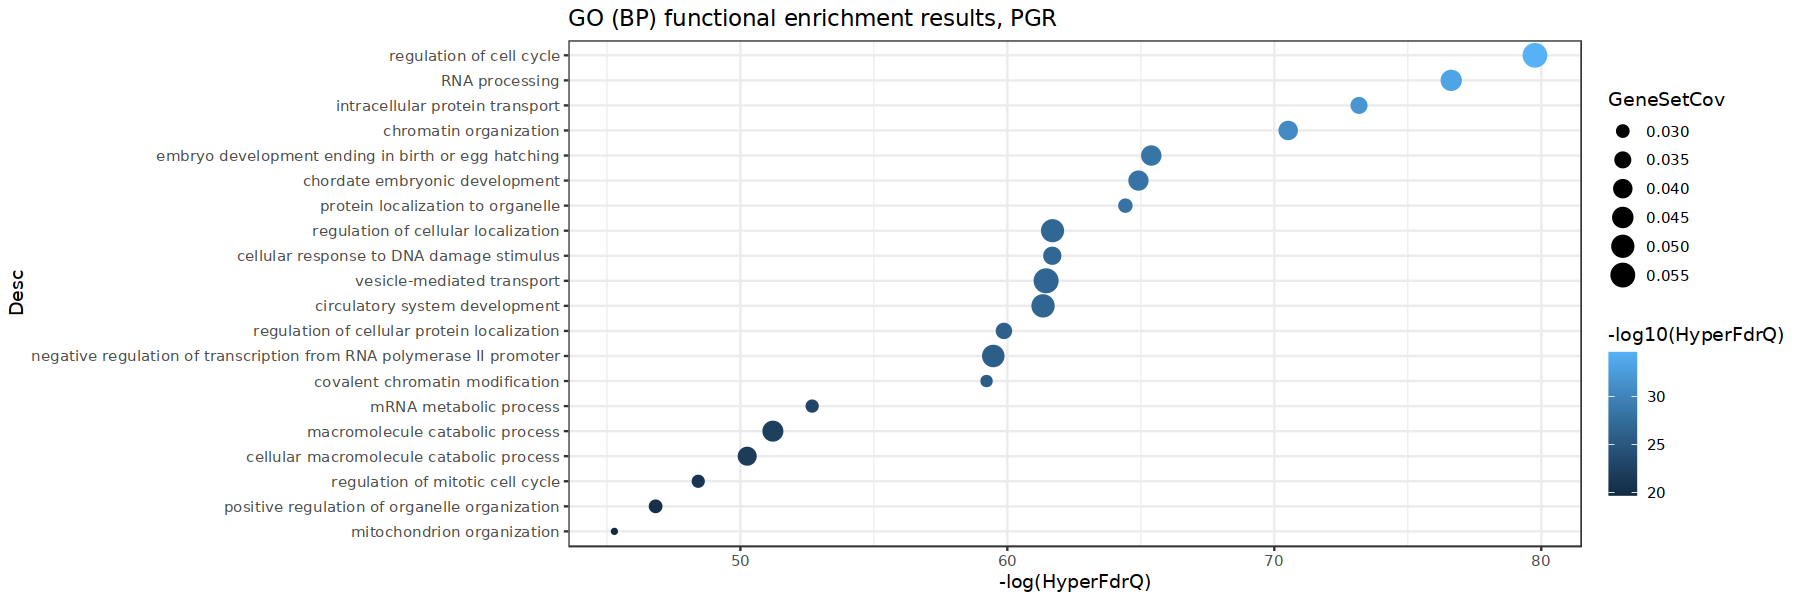

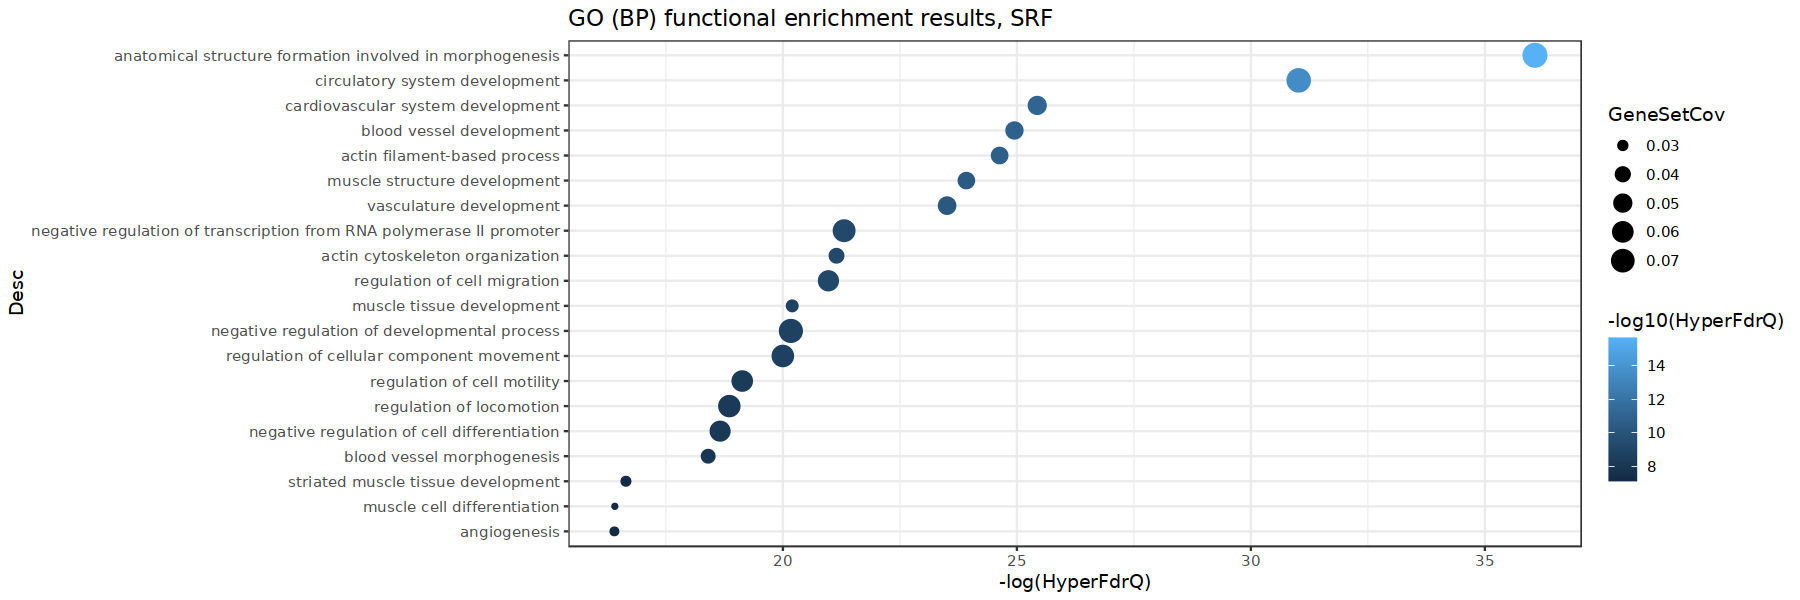

In [19]:
## Make dot plots for GO terms.

# Make the function for GO plots. See the Github link above.
# Code taken from enrichplot: https://github.com/YuLab-SMU/enrichplot/blob/devel/R/dotplot.R#L200-L207
go_plot <- function(great_go_table, title, num = 20) {
    tmp <- head(great_go_table %>% arrange(desc(-log10(HyperFdrQ))), num)
    tmp$Desc <- ordered(tmp$Desc, levels=rev(tmp$Desc))
    return(ggplot(tmp,
                  aes(y = Desc,
                      x = -log(HyperFdrQ),
                      size = GeneSetCov,
                      color = -log10(HyperFdrQ))) + geom_point() + theme_bw() + ggtitle(title))
}

# Make the actual GO plots.
go_bp_plot_pgr <- go_plot(go_bp_pgr, "GO (BP) functional enrichment results, PGR")
go_bp_plot_srf <- go_plot(go_bp_srf, "GO (BP) functional enrichment results, SRF")

# Plot the GO plots side-by-side.
saved <- options(repr.plot.width = 15, repr.plot.height = 5)
go_bp_plot_pgr
go_bp_plot_srf
options(saved)

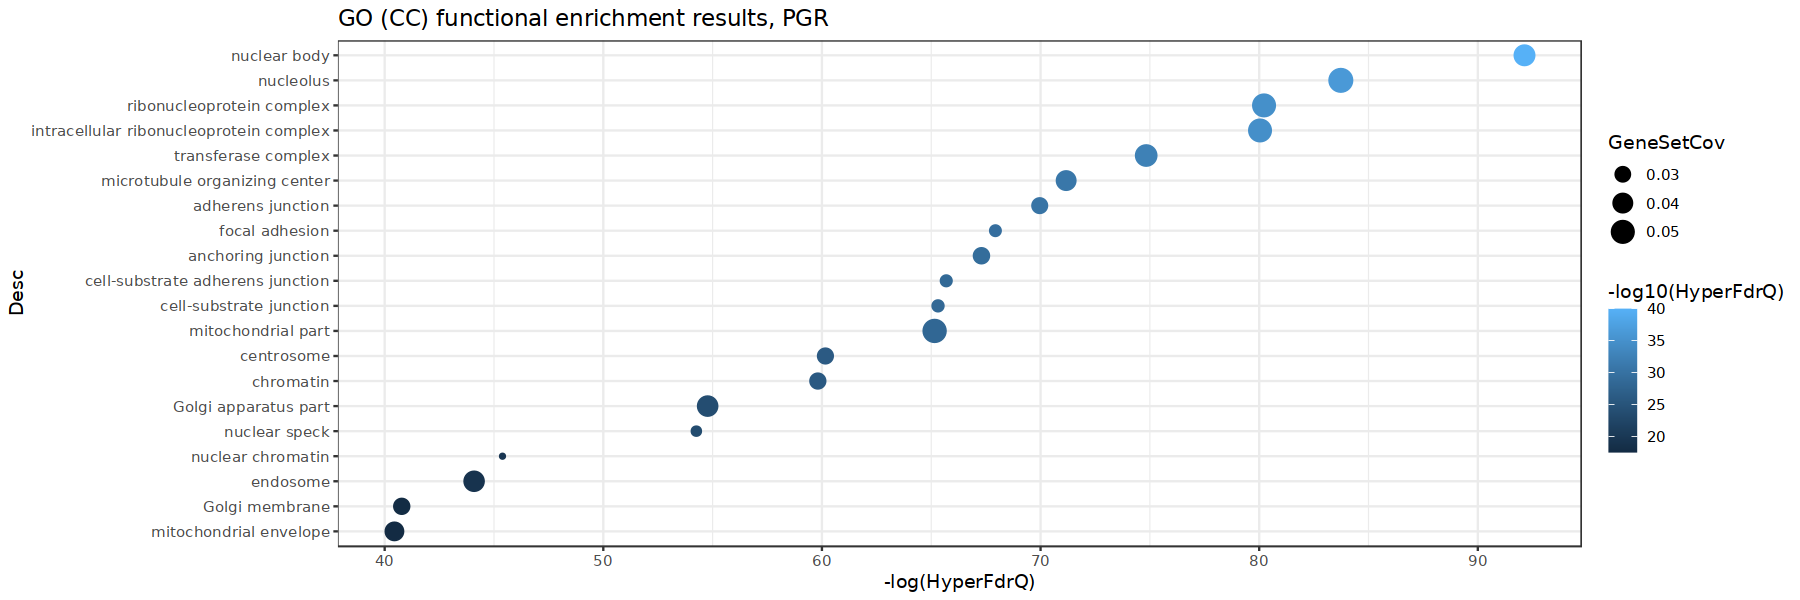

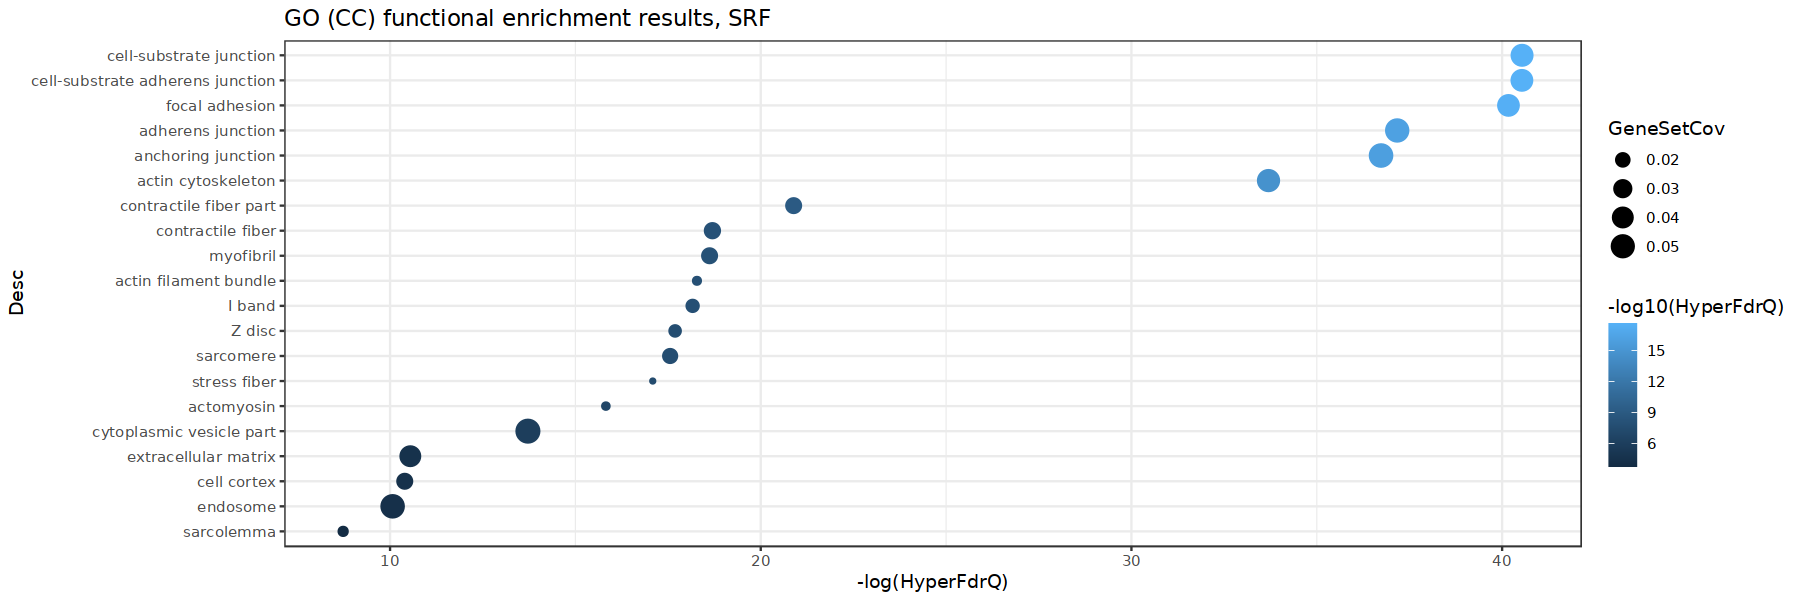

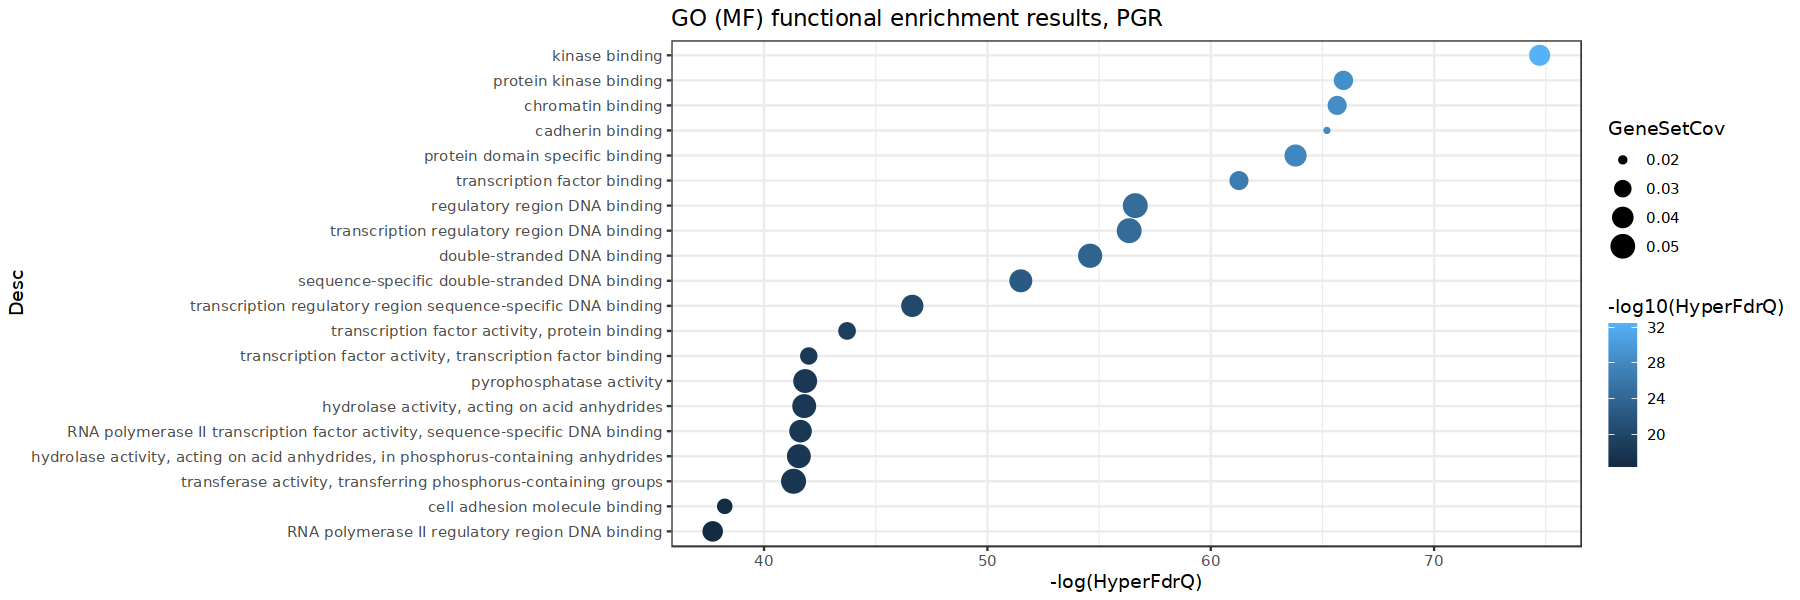

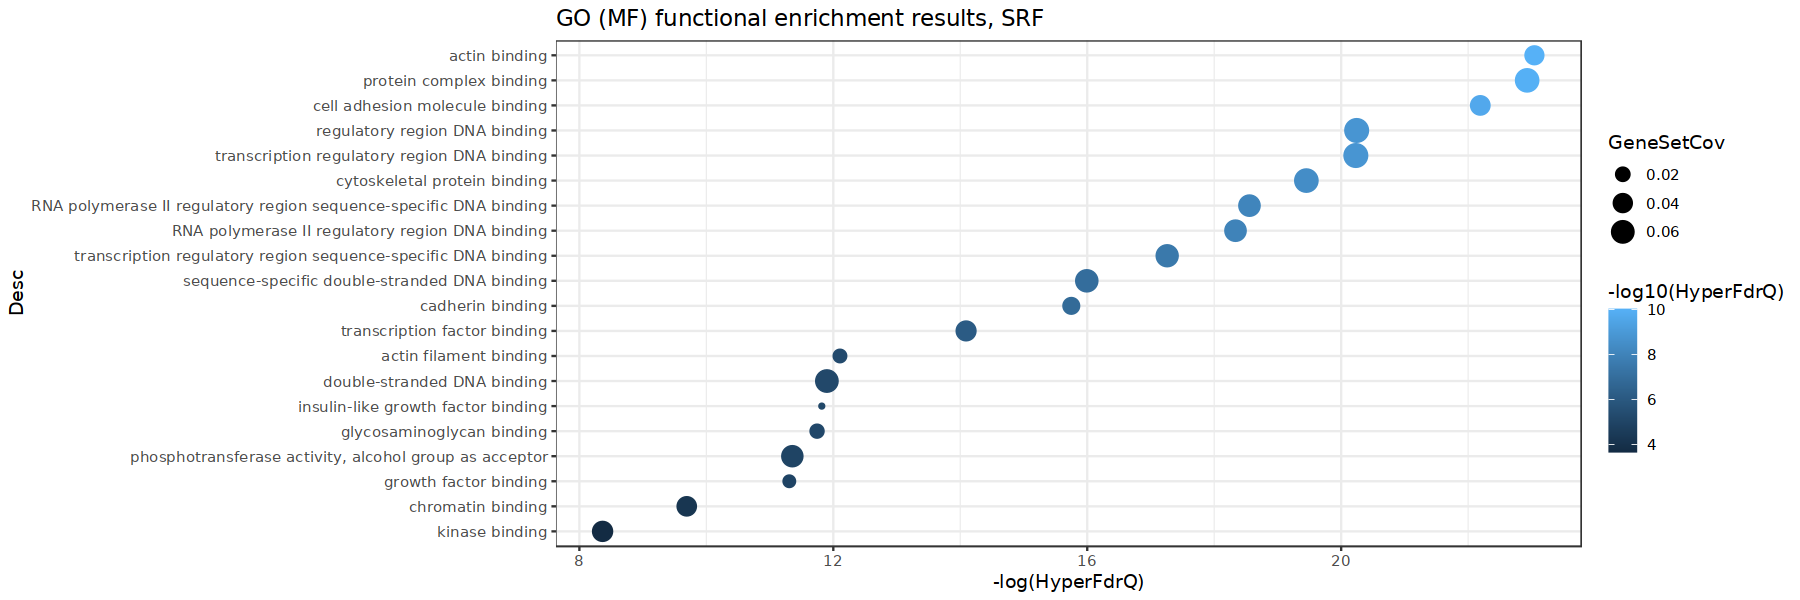

In [20]:
## Perform the above steps quickly to generate the remaining plots.

# Filter the files.
go_cc_pgr <- go_pgr %>% filter(BinomFdrQ < 0.05 & HyperFdrQ < 0.05 & `# Ontology` == "GO Cellular Component")
go_cc_srf <- go_srf %>% filter(BinomFdrQ < 0.05 & HyperFdrQ < 0.05 & `# Ontology` == "GO Cellular Component")
go_mf_pgr <- go_pgr %>% filter(BinomFdrQ < 0.05 & HyperFdrQ < 0.05 & `# Ontology` == "GO Molecular Function")
go_mf_srf <- go_srf %>% filter(BinomFdrQ < 0.05 & HyperFdrQ < 0.05 & `# Ontology` == "GO Molecular Function")

# Make the actual GO plots.
go_cc_plot_pgr <- go_plot(go_cc_pgr, "GO (CC) functional enrichment results, PGR")
go_cc_plot_srf <- go_plot(go_cc_srf, "GO (CC) functional enrichment results, SRF")
go_mf_plot_pgr <- go_plot(go_mf_pgr, "GO (MF) functional enrichment results, PGR")
go_mf_plot_srf <- go_plot(go_mf_srf, "GO (MF) functional enrichment results, SRF")

# Plot the GO plots side-by-side.
saved <- options(repr.plot.width = 15, repr.plot.height = 5)
go_cc_plot_pgr
go_cc_plot_srf
go_mf_plot_pgr
go_mf_plot_srf
options(saved)

### Identify and display common peaks using GenomicRanges

In [21]:
## Load the peak intersection output from one of the experimental groups.
## In this case, the results will be the same regardless of which we choose.

ints_pgr <- fread("results/analysis/NS50818-DeMayo-Wu/peak_intersections.txt", skip = 2)
colnames(ints_pgr) <- c("chr_pgr", "start_pgr", "end_pgr", "name_pgr", "otherfile_pgr", "strand_pgr",
                        "chr_srf", "start_srf", "end_srf", "name_srf", "otherfile_srf", "strand_srf",
                        "overlap_nbases")
head(ints_pgr)

chr_pgr,start_pgr,end_pgr,name_pgr,otherfile_pgr,strand_pgr,chr_srf,start_srf,end_srf,name_srf,otherfile_srf,strand_srf,overlap_nbases
<chr>,<int>,<int>,<chr>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<int>,<chr>,<int>
chr1,16656444,16657408,macs3_peak_74,454,+,chr1,16656842,16657207,macs3_peak_3,132,+,365
chr1,30948877,30950431,macs3_peak_136,754,+,chr1,30949919,30950227,macs3_peak_5,90,+,308
chr1,33756968,33758064,macs3_peak_144,417,+,chr1,33757431,33758099,macs3_peak_6,481,+,633
chr1,34388838,34390359,macs3_peak_158,234,+,chr1,34389463,34390013,macs3_peak_9,950,+,550
chr1,36546895,36547916,macs3_peak_193,392,+,chr1,36546839,36547203,macs3_peak_10,184,+,308
chr1,36588342,36590334,macs3_peak_201,629,+,chr1,36589068,36589926,macs3_peak_11,395,+,858


In [22]:
## First, let's generate a Venn diagram of the overlapped and nonoverlapped peaks in both regions.

# We will get the number of overlapping peaks in each gene.
# The minimum number of these two are our "overlaps."
overlaps_pgr <- length(unique(ints_pgr$name_pgr))
overlaps_srf <- length(unique(ints_pgr$name_srf))
overlaps_total <- min(overlaps_pgr, overlaps_srf)

# We then subtract the non-minimized numbers from the number of peaks in each
# annotation file. Separate peaks in one file may overlap with one peak in another.
nonoverlaps_pgr <- length(unique(annpeaks_pgr$PeakID)) - overlaps_pgr
nonoverlaps_srf <- length(unique(annpeaks_srf$PeakID)) - overlaps_srf

# Slap that into a table.
overlap_venn <- list(nonoverlaps_pgr = nonoverlaps_pgr,
                      overlaps = overlaps_total,
                      nonoverlaps_srf = nonoverlaps_srf)
overlap_venn

$nonoverlaps_pgr
[1] 32468

$overlaps
[1] 1408

$nonoverlaps_srf
[1] 814

In [23]:
## Then, let's generate a single BED file describing an overlap track for analysis in IGV.

# Make the individual GRanges objects.
granges_pgr <- GRanges(seqnames = ints_pgr$chr_pgr,
                         ranges = IRanges(ints_pgr$start_pgr, ints_pgr$end_pgr),
                         strand = ints_pgr$strand_pgr)
granges_srf <- GRanges(seqnames = ints_pgr$chr_srf,
                         ranges = IRanges(ints_pgr$start_srf, ints_pgr$end_srf),
                         strand = ints_pgr$strand_srf)

# Intersect the genomic ranges to get areas common to both.
ints_pgr_srf <- GenomicRanges::intersect(granges_pgr, granges_srf)
ints_pgr_srf

GRanges object with 1461 ranges and 0 metadata columns:
         seqnames            ranges strand
            <Rle>         <IRanges>  <Rle>
     [1]     chr1 16656842-16657207      +
     [2]     chr1 30949919-30950227      +
     [3]     chr1 33757431-33758064      +
     [4]     chr1 34389463-34390013      +
     [5]     chr1 36546895-36547203      +
     ...      ...               ...    ...
  [1457]     chrY 90765320-90765807      +
  [1458]     chrY 90772154-90772908      +
  [1459]     chrY 90774678-90775280      +
  [1460]     chrY 90779315-90779678      +
  [1461]     chrY 90784834-90785153      +
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths

In [24]:
## Write the intersections to a file. You can look at this in UCSC browser.

export.bed(ints_pgr_srf, "results/analysis/overall/PGR_SRF_overlaps.bed")

### Annotate common peaks using HOMER

I again ran the common peaks through HOMER to generate peak annotations, common peak motifs, etc.

In [25]:
##  Read in the annotations and display the first couple of entries.

bothpeaks <- fread("./results/analysis/overall/annotated_all_intersections.txt")
colnames(bothpeaks)[1] <- "PeakID"
head(bothpeaks)

PeakID,Chr,Start,End,Strand,Peak Score,Focus Ratio/Region Size,Annotation,Detailed Annotation,Distance to TSS,Nearest PromoterID,Entrez ID,Nearest Unigene,Nearest Refseq,Nearest Ensembl,Gene Name,Gene Alias,Gene Description,Gene Type
<chr>,<chr>,<int>,<int>,<chr>,<int>,<lgl>,<chr>,<chr>,<int>,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
macs3_peak_947,chr18,34860048,34861591,+,7776,NA,promoter-TSS (NM_007913),promoter-TSS (NM_007913),-388,NM_007913,13653,Mm.181959,NM_007913,ENSMUSG00000038418,Egr1,A530045N19Rik|ETR103|Egr-1|Krox-1|Krox-24|Krox24|NGF1-A|NGFI-A|NGFIA|TIS8|Zenk|Zfp-6|Zif268|egr,early growth response 1,protein-coding
macs3_peak_642,chr14,70074558,70075542,+,6543,NA,Intergenic,CpG,-2267,NM_001289925,13655,Mm.103737,NM_018781,ENSMUSG00000033730,Egr3,Pilot,early growth response 3,protein-coding
macs3_peak_550,chr13,93303374,93304031,+,6213,NA,promoter-TSS (NM_147176),promoter-TSS (NM_147176),-55,NM_011982,26556,Mm.37533,NM_011982,ENSMUSG00000007617,Homer1,PSD-Zip45|SYN47|Ves-1|homer-1|vesl-1,homer scaffolding protein 1,protein-coding
macs3_peak_384,chr11,103267230,103267996,+,5919,NA,promoter-TSS (NM_016896),promoter-TSS (NM_016896),-212,NM_016896,53859,Mm.158981,NM_016896,ENSMUSG00000020941,Map3k14,Nik|aly,mitogen-activated protein kinase kinase kinase 14,protein-coding
macs3_peak_564,chr13,107889915,107890645,+,5580,NA,promoter-TSS (NM_145456),promoter-TSS (NM_145456),-216,NM_145456,67263,Mm.490418,NM_145456,,Zswim6,2900036G02Rik|mKIAA1577,zinc finger SWIM-type containing 6,protein-coding
macs3_peak_325,chr11,69661856,69662723,+,5531,NA,promoter-TSS (NR_035455),promoter-TSS (NR_035455),360,NM_001301711,24070,Mm.89579,NM_011900,ENSMUSG00000018761,Mpdu1,LEC35|SL15|Supl15h,mannose-P-dolichol utilization defect 1,protein-coding



      3' UTR       5' UTR         EXON   INTERGENIC       INTRON   NON-CODING 
   0.3434066    1.5109890    0.6868132   23.2829670   29.9450549    0.4120879 
PROMOTER-TSS          TTS 
  42.3763736    1.4423077 

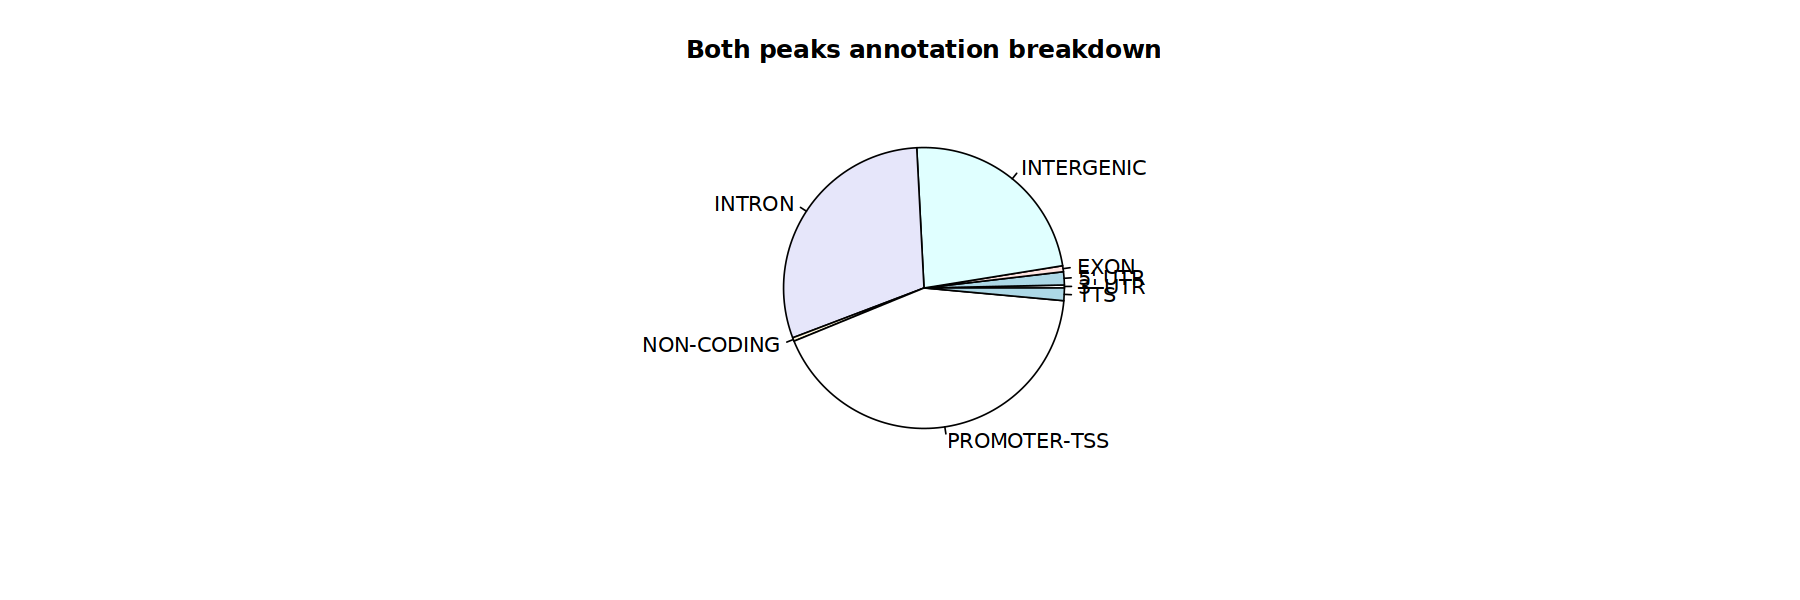

In [26]:
## Same as analogous cell above.

# Scrape annotation types from each run.
bothdist <- generate_anndist(bothpeaks$Annotation)

# Display the percentages.
bothdist / sum(bothdist) * 100

# Display the annotation types.
pie(bothdist, main = "Both peaks annotation breakdown")

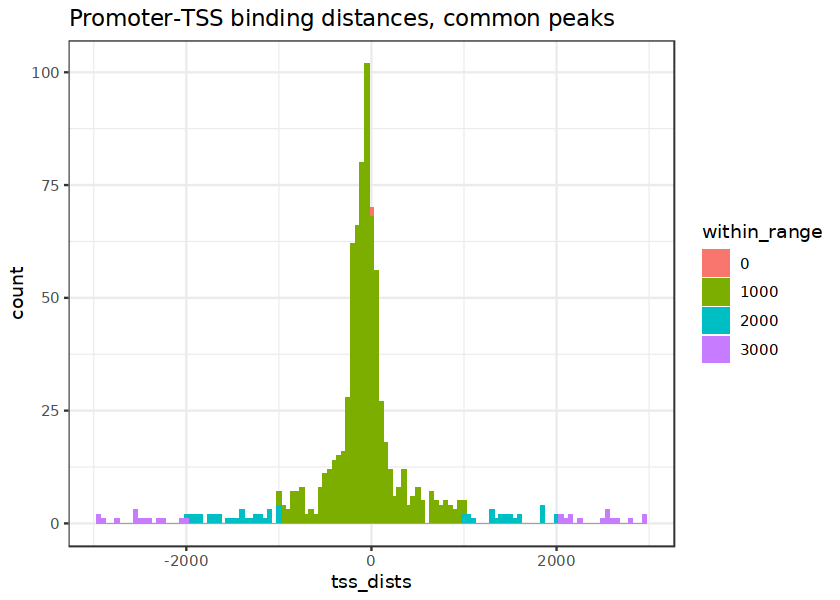

In [27]:
## Plot the distributions for TSS sites.

coarseanns_both <- coarse_anns(bothpeaks$Annotation)
tss_dists_both <- bothpeaks[["Distance to TSS"]]

saved <- options(repr.plot.width = 7)
create_tss_hist(tss_dists_both, title = "Promoter-TSS binding distances, common peaks")
options(saved)

### Find enriched GO pathways of common peaks using GREAT

Same procedure as above.

In [28]:
## Load the GO data.

go_ints <- fread("./results/analysis/overall/gene_ontology_all_intersections/great/all.tsv", sep = "\t", fill = TRUE, skip = 3)
head(go_ints)

# Ontology,ID,Desc,BinomRank,BinomP,BinomBonfP,BinomFdrQ,RegionFoldEnrich,ExpRegions,ObsRegions,⋯,HyperBonfP,HyperFdrQ,GeneFoldEnrich,ExpGenes,ObsGenes,TotalGenes,GeneSetCov,TermCov,Regions,Genes
<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<dbl>,<chr>,<chr>
Ensembl Genes,15687,Pdia4,1,1.615296e-73,3.455926e-69,3.455926e-69,342.60350,0.099240080,34,⋯,1,1,11.55238,0.08656228,1,1,0.0005399568,1,"macs3_peak_1636,macs3_peak_1637,macs3_peak_1638,macs3_peak_1639,macs3_peak_1640,macs3_peak_1641,macs3_peak_1642,macs3_peak_1643,macs3_peak_1644,macs3_peak_1645,macs3_peak_1646,macs3_peak_1647,macs3_peak_1648,macs3_peak_1649,macs3_peak_1650,macs3_peak_1651,macs3_peak_1652,macs3_peak_1653,macs3_peak_1654,macs3_peak_1655,macs3_peak_1656,macs3_peak_1657,macs3_peak_1658,macs3_peak_1659,macs3_peak_1660,macs3_peak_1661,macs3_peak_1662,macs3_peak_1663,macs3_peak_1664,macs3_peak_1665,macs3_peak_1666,macs3_peak_1667,macs3_peak_1668,macs3_peak_1669",Pdia4
Ensembl Genes,15686,Ezh2,2,1.206331e-65,2.580945e-61,1.290473e-61,200.62060,0.169474100,34,⋯,1,1,11.55238,0.08656228,1,1,0.0005399568,1,"macs3_peak_1636,macs3_peak_1637,macs3_peak_1638,macs3_peak_1639,macs3_peak_1640,macs3_peak_1641,macs3_peak_1642,macs3_peak_1643,macs3_peak_1644,macs3_peak_1645,macs3_peak_1646,macs3_peak_1647,macs3_peak_1648,macs3_peak_1649,macs3_peak_1650,macs3_peak_1651,macs3_peak_1652,macs3_peak_1653,macs3_peak_1654,macs3_peak_1655,macs3_peak_1656,macs3_peak_1657,macs3_peak_1658,macs3_peak_1659,macs3_peak_1660,macs3_peak_1661,macs3_peak_1662,macs3_peak_1663,macs3_peak_1664,macs3_peak_1665,macs3_peak_1666,macs3_peak_1667,macs3_peak_1668,macs3_peak_1669",Ezh2
Ensembl Genes,9133,Il17b,3,5.080060e-14,1.086879e-09,3.622929e-10,96.41483,0.082974790,8,⋯,1,1,11.55238,0.08656228,1,1,0.0005399568,1,"macs3_peak_965,macs3_peak_965,macs3_peak_966,macs3_peak_967,macs3_peak_968,macs3_peak_969,macs3_peak_970,macs3_peak_971",Il17b
Ensembl Genes,9132,Csnk1a1,4,3.217978e-12,6.884864e-08,1.721216e-08,89.71121,0.078028150,7,⋯,1,1,11.55238,0.08656228,1,1,0.0005399568,1,"macs3_peak_964,macs3_peak_965,macs3_peak_965,macs3_peak_966,macs3_peak_967,macs3_peak_968,macs3_peak_969",Csnk1a1
Ensembl Genes,18811,Rbpms,5,7.352060e-10,1.572973e-05,3.145946e-06,40.81595,0.171501600,7,⋯,1,1,11.55238,0.08656228,1,1,0.0005399568,1,"macs3_peak_1937,macs3_peak_1938,macs3_peak_1939,macs3_peak_1940,macs3_peak_1941,macs3_peak_1942,macs3_peak_1943",Rbpms
Ensembl Genes,20819,mt-Cytb,6,1.020766e-08,2.183929e-04,3.639881e-05,759.80750,0.003948369,3,⋯,1,1,11.55238,0.08656228,1,1,0.0005399568,1,"macs3_peak_2178,macs3_peak_2178,macs3_peak_2179",mt-Cytb


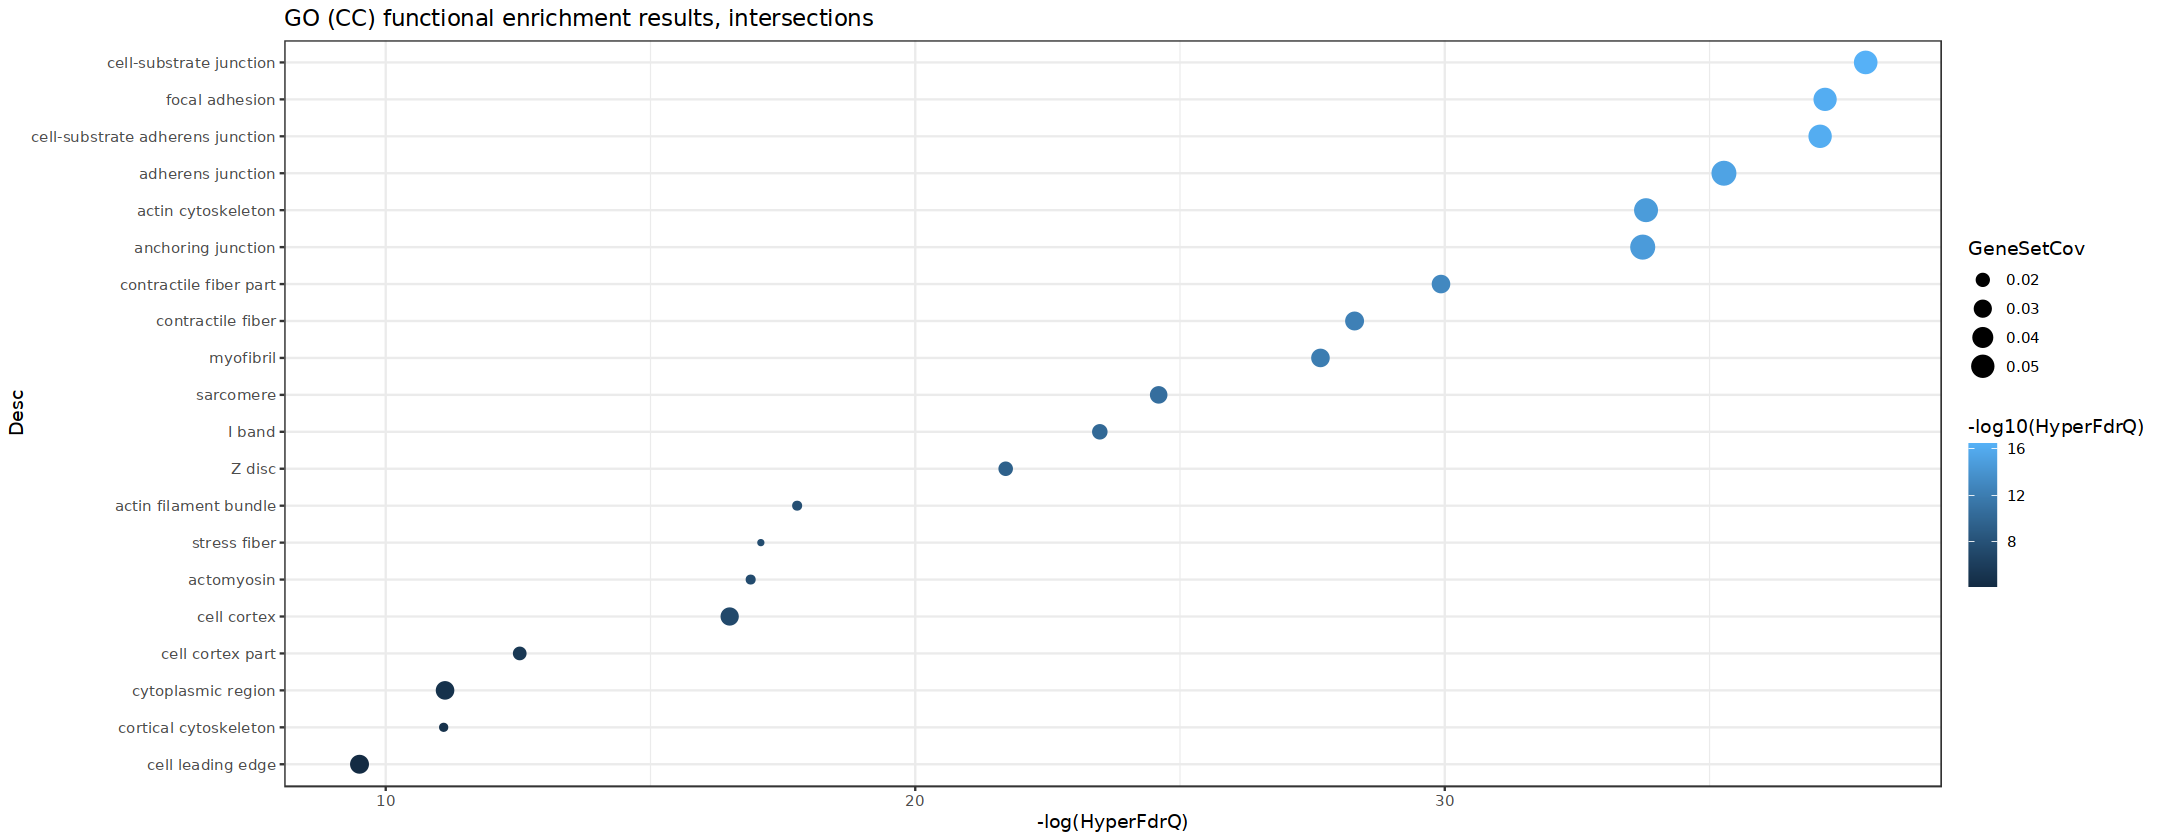

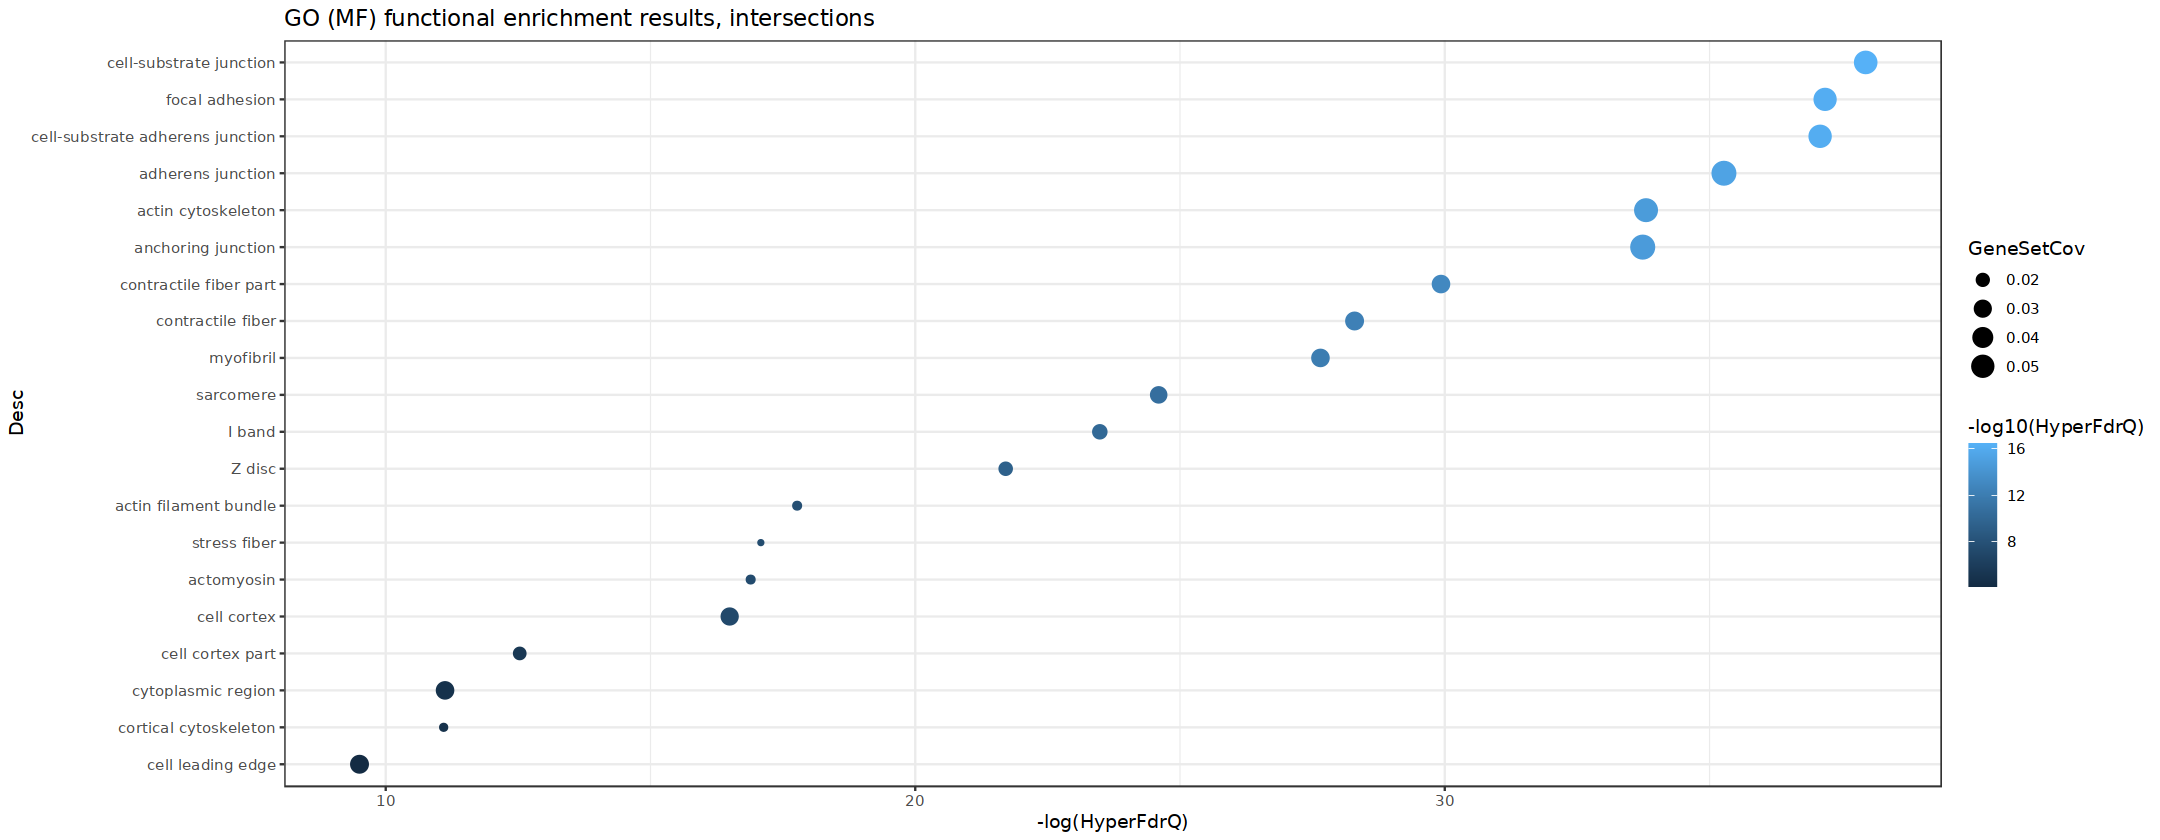

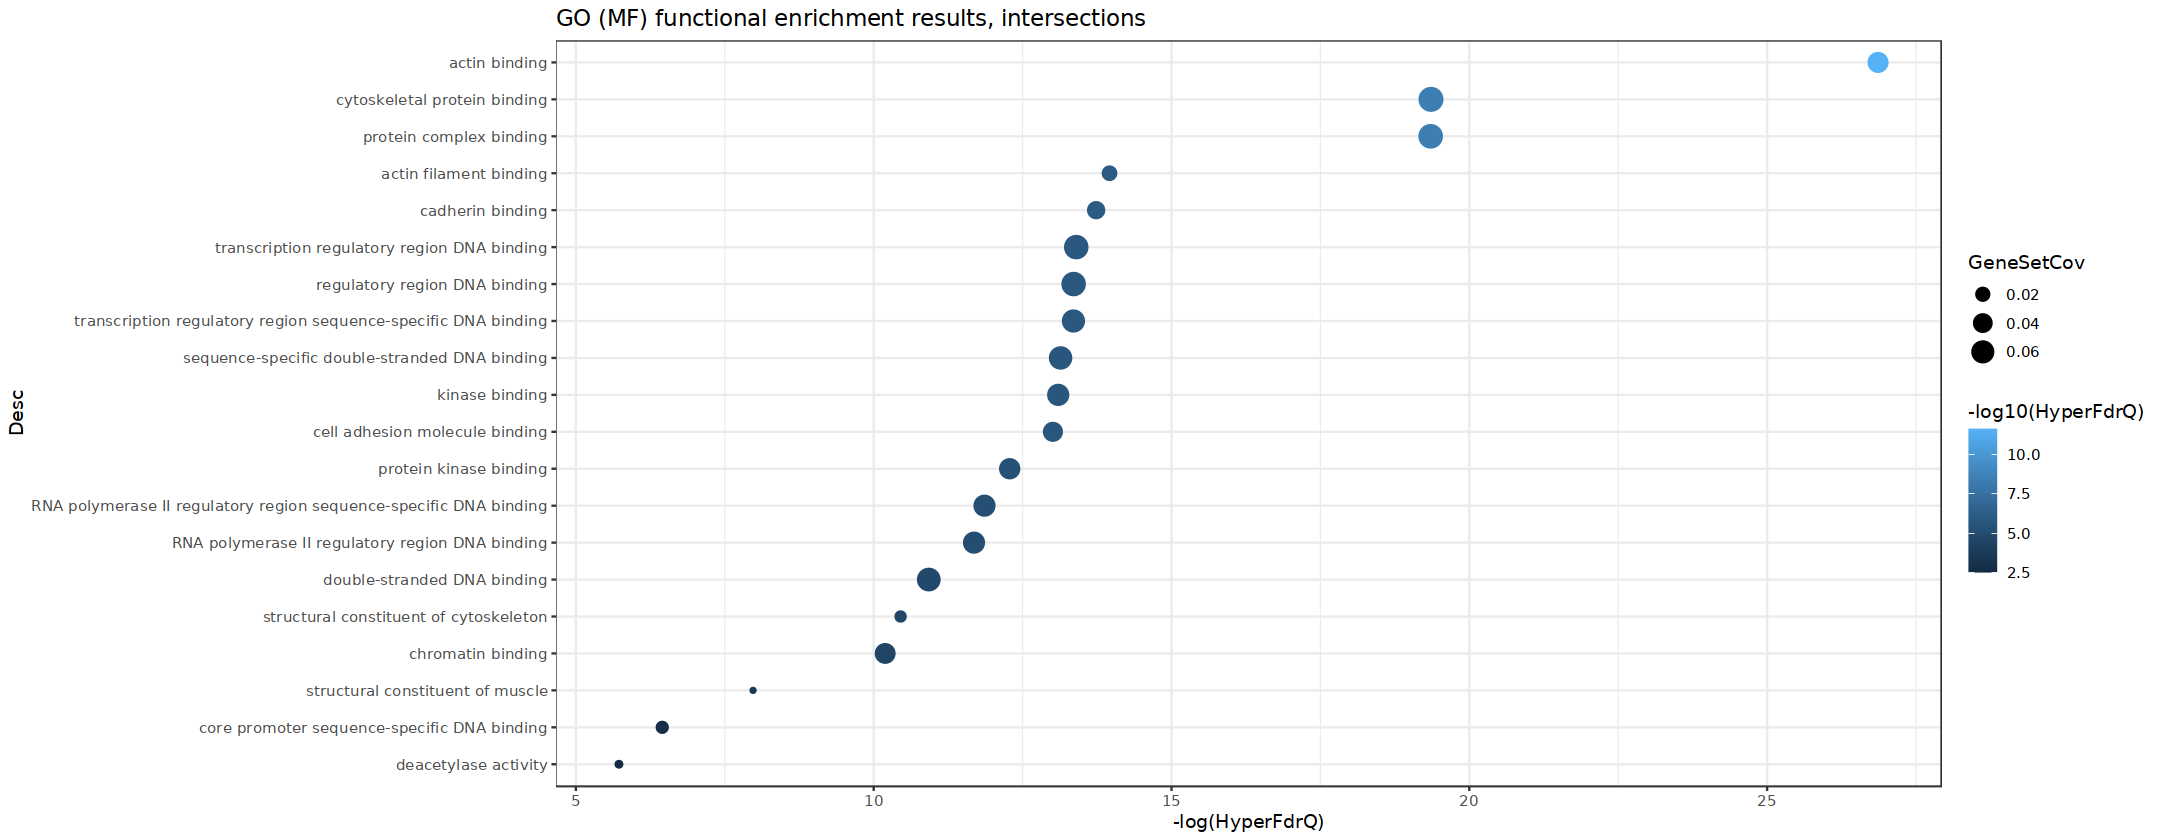

In [31]:
## Process and show the GO data.

# Filter the files.
go_bp_ints <- go_ints %>% filter(BinomFdrQ < 0.05 & HyperFdrQ < 0.05 & `# Ontology` == "GO Cellular Component")
go_cc_ints <- go_ints %>% filter(BinomFdrQ < 0.05 & HyperFdrQ < 0.05 & `# Ontology` == "GO Cellular Component")
go_mf_ints <- go_ints %>% filter(BinomFdrQ < 0.05 & HyperFdrQ < 0.05 & `# Ontology` == "GO Molecular Function")

# Make the actual GO plots.
go_bp_plot_ints <- go_plot(go_bp_ints, "GO (CC) functional enrichment results, intersections")
go_cc_plot_ints <- go_plot(go_cc_ints, "GO (MF) functional enrichment results, intersections")
go_mf_plot_ints <- go_plot(go_mf_ints, "GO (MF) functional enrichment results, intersections")

saved <- options(repr.plot.width = 18, repr.plot.height = 7)
go_bp_plot_ints
go_cc_plot_ints
go_mf_plot_ints
options(saved)